In [1]:
import kagglehub

path = kagglehub.dataset_download("kartik2112/fraud-detection")

print("Path to dataset files:", path)

Path to dataset files: /kaggle/input/fraud-detection


In [8]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
df=pd.read_csv(path+"/fraudTrain.csv")
df.head(5)

,Unnamed: 0,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,...,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,0,2019-01-01 00:00:18,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,561 Perry Cove,...,36.0788,-81.1781,3495,"Psychologist, counselling",1988-03-09,0b242abb623afc578575680df30655b9,1325376018,36.011293,-82.048315,0
1,1,2019-01-01 00:00:44,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,...,48.8878,-118.2105,149,Special educational needs teacher,1978-06-21,1f76529f8574734946361c461b024d99,1325376044,49.159047,-118.186462,0
2,2,2019-01-01 00:00:51,38859492057661,fraud_Lind-Buckridge,entertainment,220.11,Edward,Sanchez,M,594 White Dale Suite 530,...,42.1808,-112.2620,4154,Nature conservation officer,1962-01-19,a1a22d70485983eac12b5b88dad1cf95,1325376051,43.150704,-112.154481,0
3,3,2019-01-01 00:01:16,3534093764340240,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,Jeremy,White,M,9443 Cynthia Court Apt. 038,...,46.2306,-112.1138,1939,Patent attorney,1967-01-12,6b849c168bdad6f867558c3793159a81,1325376076,47.034331,-112.561071,0
4,4,2019-01-01 00:03:06,375534208663984,fraud_Keeling-Crist,misc_pos,41.96,Tyler,Garcia,M,408 Bradley Rest,...,38.4207,-79.4629,99,Dance movement psychotherapist,1986-03-28,a41d7549acf90789359a9aa5346dcb46,1325376186,38.674999,-78.632459,0


In [5]:
print(f"Total transactions: {len(df)}")
print(f"Number of features: {len(df.columns)}")
print(f"Fraud cases: {df['is_fraud'].sum()} ({df['is_fraud'].mean()*100:.2f}% of total)")

Total transactions: 1296675
Number of features: 23
Fraud cases: 7506 (0.58% of total)


In [10]:
print("\nFraud distribution:\n", df['is_fraud'].value_counts(normalize=True))


Fraud distribution:
 is_fraud
0    0.994211
1    0.005789
Name: proportion, dtype: float64


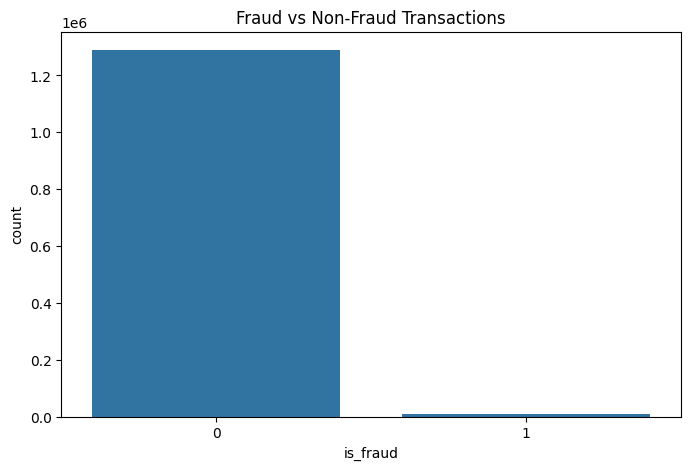

                 amt                  
                mean   median    count
is_fraud                              
0          67.667110   47.280  1289169
1         531.320092  396.505     7506


In [11]:
plt.figure(figsize=(8,5))
sns.countplot(x='is_fraud', data=df)
plt.title('Fraud vs Non-Fraud Transactions')
plt.show()
fraud_stats = df.groupby('is_fraud').agg({'amt': ['mean', 'median', 'count']})
print(fraud_stats)

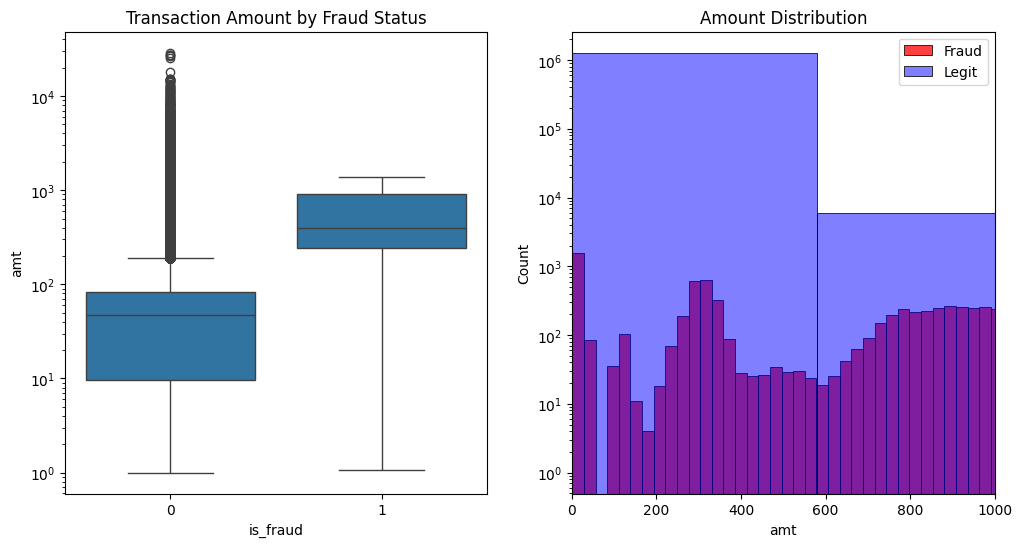

In [12]:
plt.figure(figsize=(12,6))
plt.subplot(1,2,1)
sns.boxplot(x='is_fraud', y='amt', data=df)
plt.yscale('log')
plt.title('Transaction Amount by Fraud Status')

plt.subplot(1,2,2)
sns.histplot(df[df['is_fraud']==1]['amt'], bins=50, color='red', label='Fraud')
sns.histplot(df[df['is_fraud']==0]['amt'], bins=50, color='blue', alpha=0.5, label='Legit')
plt.xlim(0, 1000)
plt.yscale('log')
plt.title('Amount Distribution')
plt.legend()
plt.show()

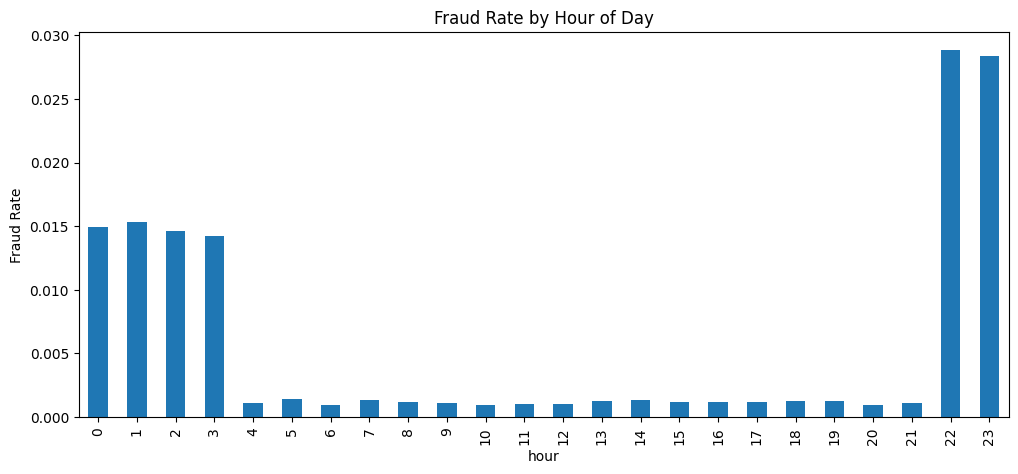

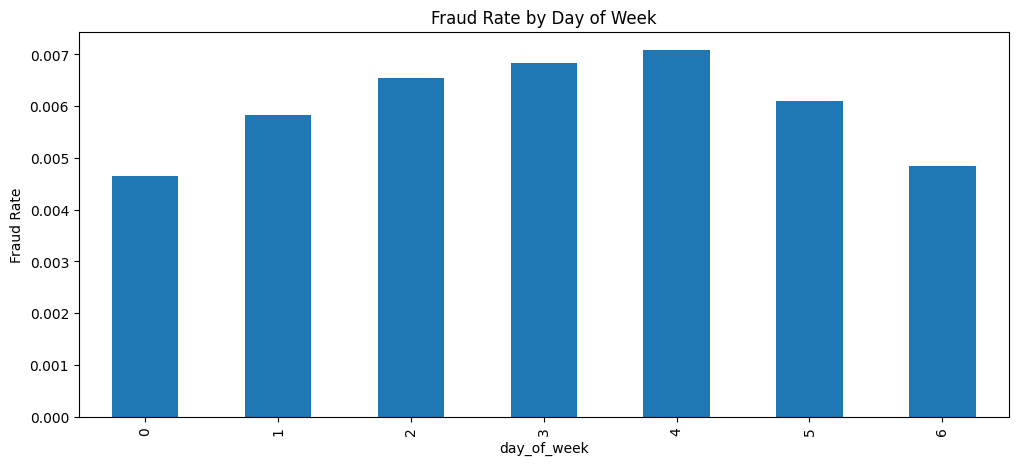

In [13]:
df['trans_date_trans_time'] = pd.to_datetime(df['trans_date_trans_time'])
df['hour'] = df['trans_date_trans_time'].dt.hour
df['day_of_week'] = df['trans_date_trans_time'].dt.dayofweek
df['month'] = df['trans_date_trans_time'].dt.month

plt.figure(figsize=(12,5))
df.groupby('hour')['is_fraud'].mean().plot(kind='bar')
plt.title('Fraud Rate by Hour of Day')
plt.ylabel('Fraud Rate')
plt.show()

plt.figure(figsize=(12,5))
df.groupby('day_of_week')['is_fraud'].mean().plot(kind='bar')
plt.title('Fraud Rate by Day of Week')
plt.ylabel('Fraud Rate')
plt.show()

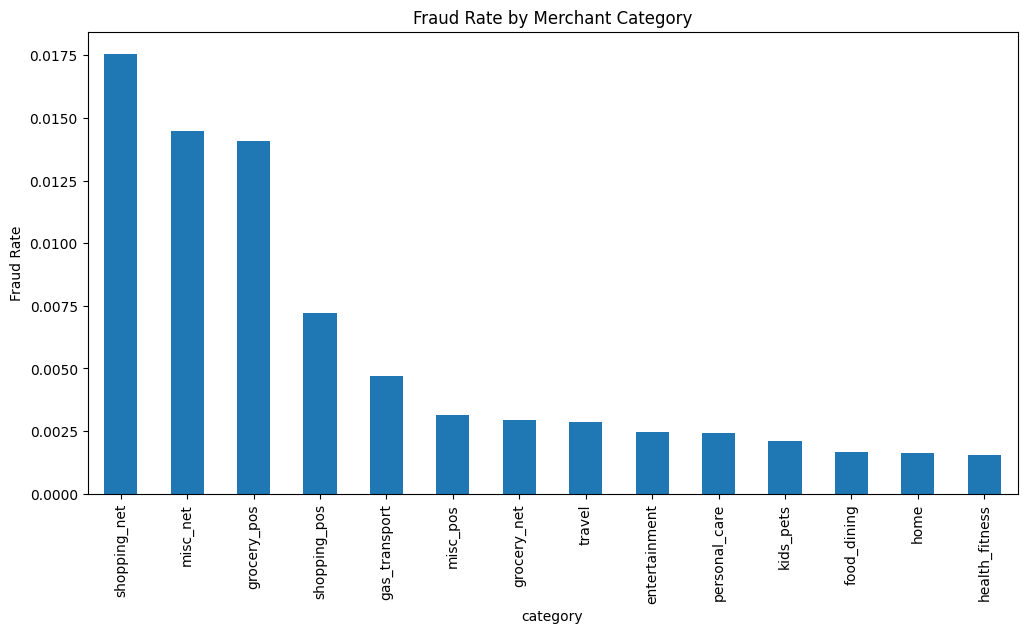

In [14]:
plt.figure(figsize=(12,6))
category_fraud = df.groupby('category')['is_fraud'].mean().sort_values(ascending=False)
category_fraud.plot(kind='bar')
plt.title('Fraud Rate by Merchant Category')
plt.ylabel('Fraud Rate')
plt.show()

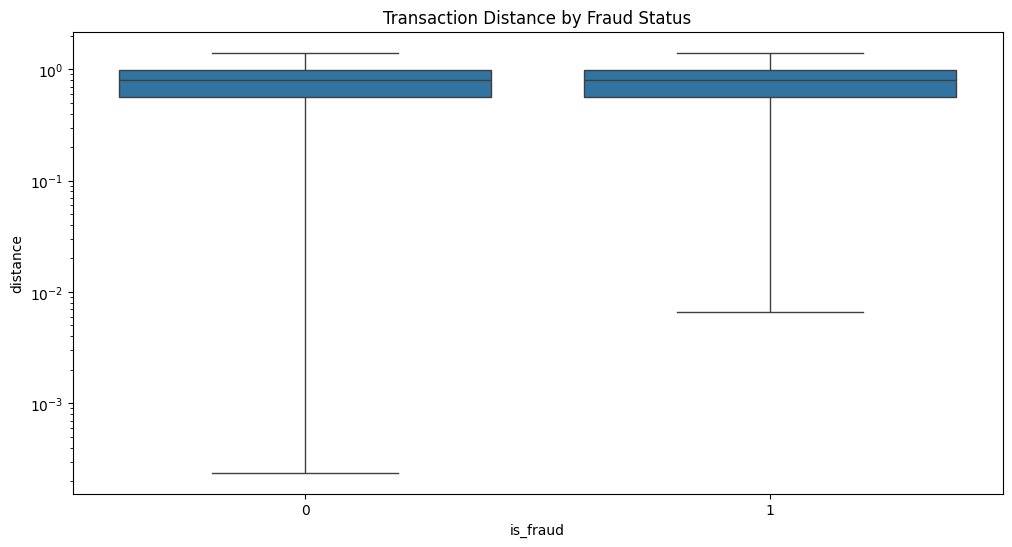

In [15]:
df['distance'] = ((df['lat']-df['merch_lat'])**2 + (df['long']-df['merch_long'])**2)**0.5

plt.figure(figsize=(12,6))
sns.boxplot(x='is_fraud', y='distance', data=df)
plt.yscale('log')
plt.title('Transaction Distance by Fraud Status')
plt.show()

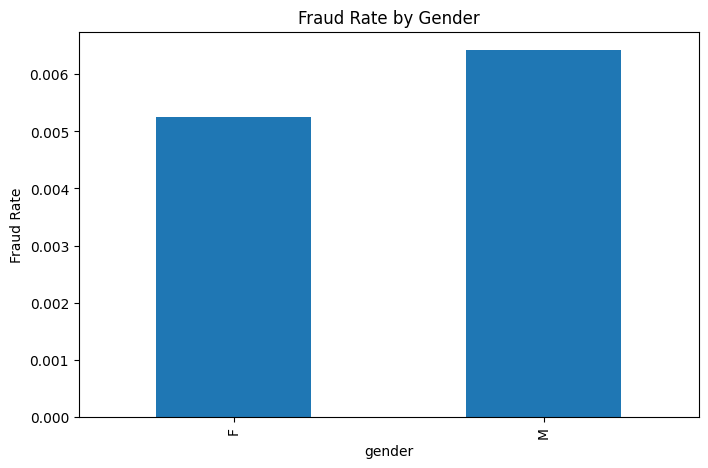

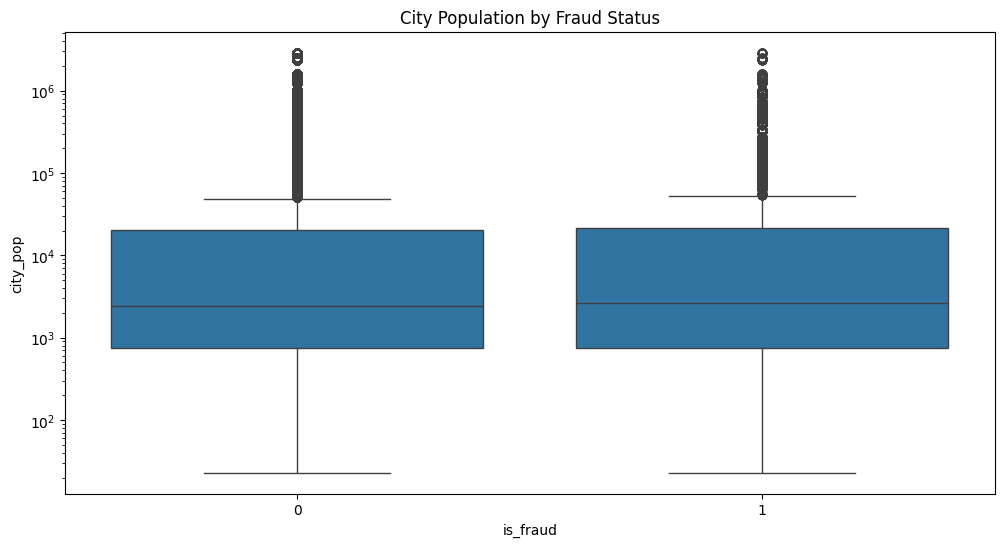

In [16]:
plt.figure(figsize=(8,5))
df.groupby('gender')['is_fraud'].mean().plot(kind='bar')
plt.title('Fraud Rate by Gender')
plt.ylabel('Fraud Rate')
plt.show()

plt.figure(figsize=(12,6))
sns.boxplot(x='is_fraud', y='city_pop', data=df)
plt.yscale('log')
plt.title('City Population by Fraud Status')
plt.show()

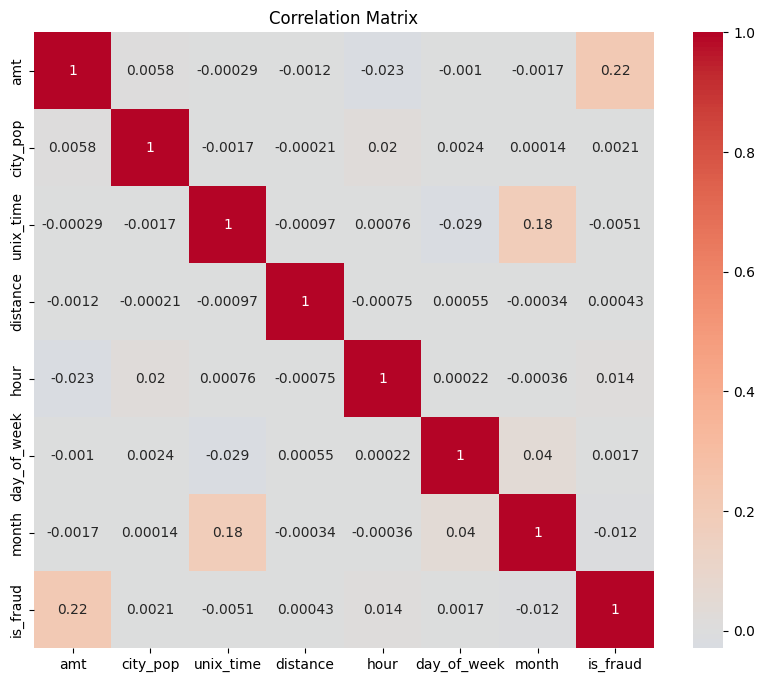


Point-Biserial Correlations with Fraud:
             Correlation
amt             0.219404
hour            0.013799
city_pop        0.002136
day_of_week     0.001739
distance        0.000434
unix_time      -0.005078
month          -0.012409


In [18]:
numerical_df = df[['amt', 'city_pop', 'unix_time', 'distance', 'hour', 'day_of_week', 'month', 'is_fraud']]

plt.figure(figsize=(10,8))
sns.heatmap(numerical_df.corr(), annot=True, cmap='coolwarm', center=0)
plt.title('Correlation Matrix')
plt.show()

from scipy.stats import pointbiserialr

correlations = {}
for col in numerical_df.columns[:-1]:
    corr, _ = pointbiserialr(numerical_df[col], numerical_df['is_fraud'])
    correlations[col] = corr

corr_df = pd.DataFrame.from_dict(correlations, orient='index', columns=['Correlation'])
print("\nPoint-Biserial Correlations with Fraud:")
print(corr_df.sort_values('Correlation', ascending=False))